Lab - Data Visualization 

Conor Murray

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('SPSS_cars_v2.csv')
df.head()

,manufact,model,sales,resale,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,country
0,Acura,Integra,16.92,16.360,21.5,1.8,140,101.2,67.3,172.4,2.639,13.2,28.0,Japan
1,Acura,TL,39.38,19.875,28.4,3.2,225,108.1,70.3,192.9,3.517,17.2,25.0,Japan
2,Acura,CL,14.11,18.225,NaN,3.2,225,106.9,70.6,192.0,3.470,17.2,26.0,Japan
3,Acura,RL,8.59,29.725,42.0,3.5,210,114.6,71.4,196.6,3.850,18.0,22.0,Japan
4,Cadillac,DeVille,63.73,22.525,39.9,4.6,275,115.3,74.5,207.2,3.978,18.5,22.0,United States


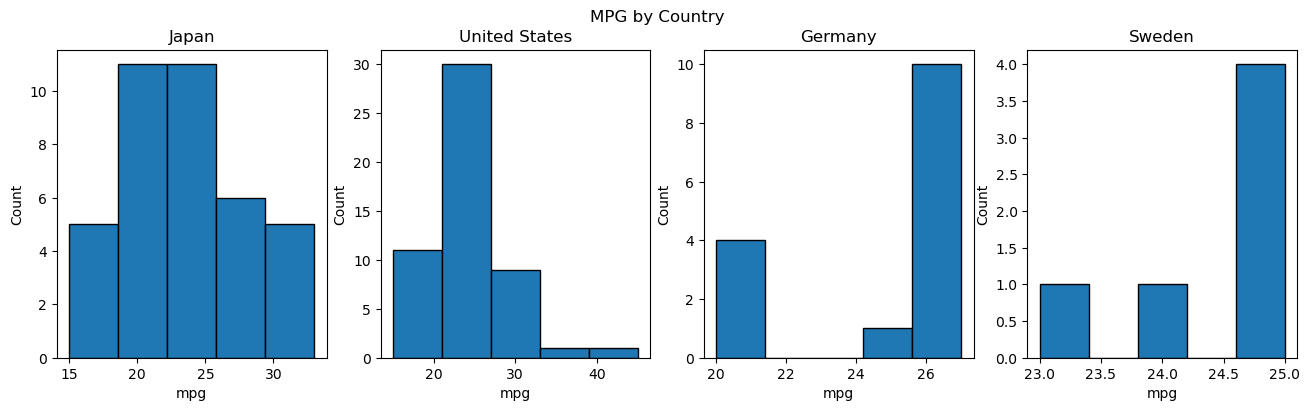

In [32]:
mask = df['mpg'].notna()
df_mpg = df[mask]
countries = df_mpg['country'].unique()
n = len(countries)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
for i in range(n):
    country = countries[i]
    country_mask = df_mpg['country'] == country
    axes[i].hist(df_mpg[country_mask]['mpg'], bins=5, edgecolor='black')
    axes[i].set_title(country)
    axes[i].set_xlabel('mpg')
    axes[i].set_ylabel('Count')
fig.suptitle('MPG by Country')
plt.show()

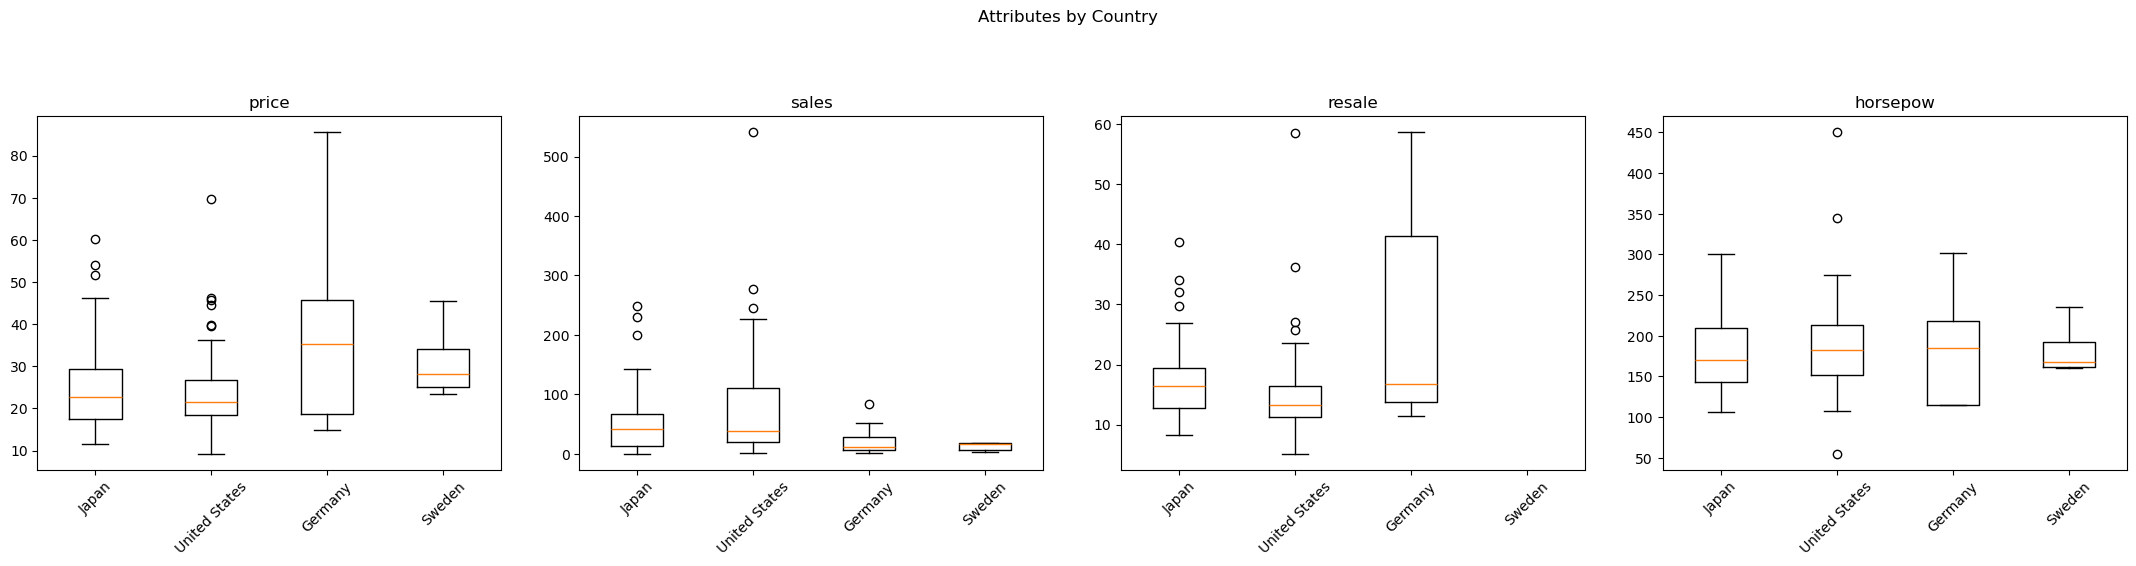

In [33]:
attributes = ['price', 'sales', 'resale', 'horsepow']
countries = df['country'].unique()
fig, axes = plt.subplots(1, len(attributes), figsize=(22, 6))
for i in range(len(attributes)):
    attr = attributes[i]
    data_list = []
    for country in countries:
        mask = (df['country'] == country) & (df[attr].notna())
        data_list.append(df[mask][attr])
    axes[i].boxplot(data_list)
    axes[i].set_xticklabels(countries)
    axes[i].set_title(attr)
    axes[i].tick_params(axis='x', rotation=45)
fig.suptitle('Attributes by Country')
fig.tight_layout(pad=3)
plt.show()

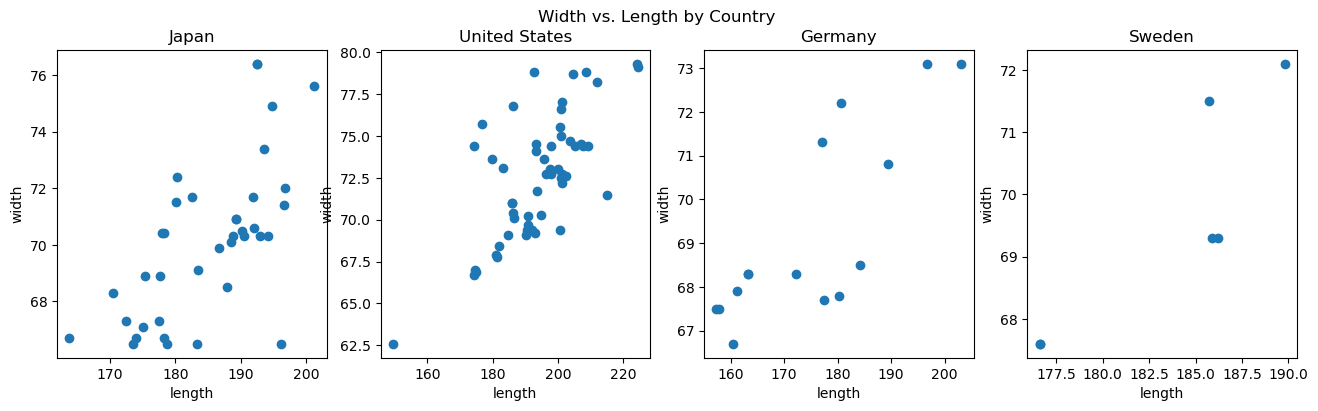

In [34]:
countries = df['country'].unique()
n = len(countries)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
for i in range(n):
    country = countries[i]
    mask = df['country'] == country
    axes[i].scatter(df[mask]['length'], df[mask]['width'])
    axes[i].set_title(country)
    axes[i].set_xlabel('length')
    axes[i].set_ylabel('width')
fig.suptitle('Width vs. Length by Country')
plt.show()

manufact
Cadillac       5
Chevrolet      9
Chrysler       6
Dodge         11
Ford          11
Oldsmobile     6
Pontiac        6
Name: model, dtype: int64


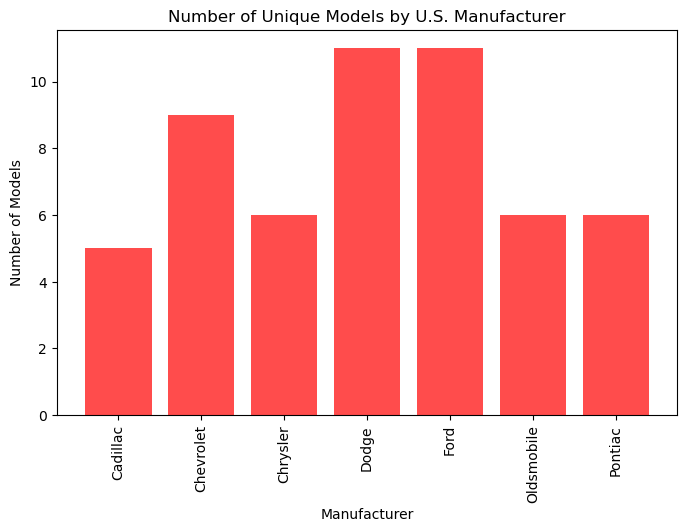

In [35]:
mask = df['country'] == 'United States'
us = df[mask]
us_counts = us.groupby('manufact')['model'].nunique()
print(us_counts)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(us_counts.index, us_counts.values, color='red', alpha=0.7)
ax.set_title('Number of Unique Models by U.S. Manufacturer')
ax.set_xlabel('Manufacturer')
ax.set_ylabel('Number of Models')
ax.tick_params(axis='x', rotation=90)
plt.show()

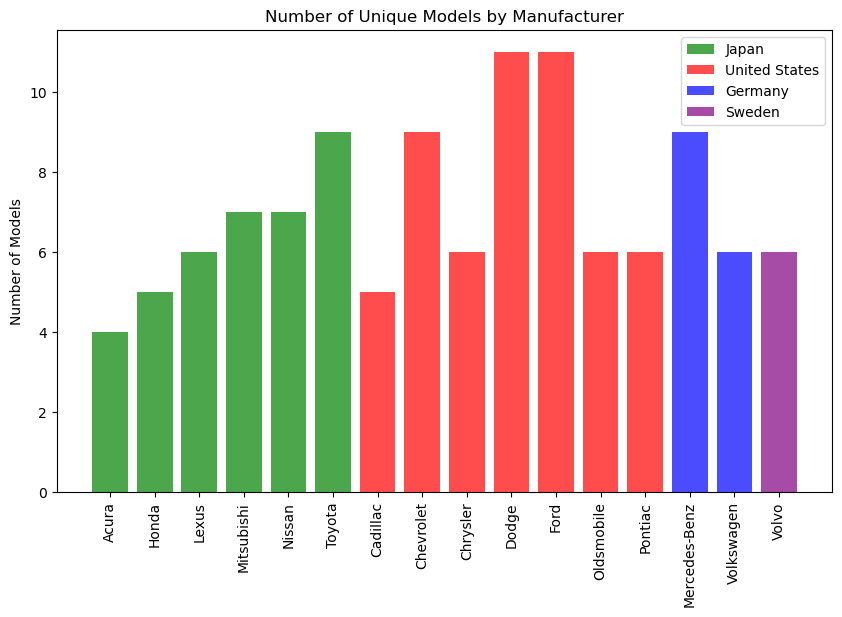

In [36]:
countries = df['country'].unique()
colors = ['green', 'red', 'blue', 'purple']
fig, ax = plt.subplots(figsize=(10, 6))
position = 0
all_positions = []
all_names = []
for i in range(len(countries)):
    country = countries[i]
    mask = df['country'] == country
    counts = df[mask].groupby('manufact')['model'].nunique()
    positions = []
    for j in range(len(counts)):
        positions.append(position)
        all_positions.append(position)
        all_names.append(counts.index[j])
        position = position + 1
    ax.bar(positions, counts.values, color=colors[i], alpha=0.7, label=country)
ax.set_xticks(all_positions)
ax.set_xticklabels(all_names, rotation=90)
ax.set_ylabel('Number of Models')
ax.set_title('Number of Unique Models by Manufacturer')
ax.legend()
plt.show()

country
United States    4297.15
Japan            2099.28
Germany           326.33
Sweden             75.75
Name: sales, dtype: float64


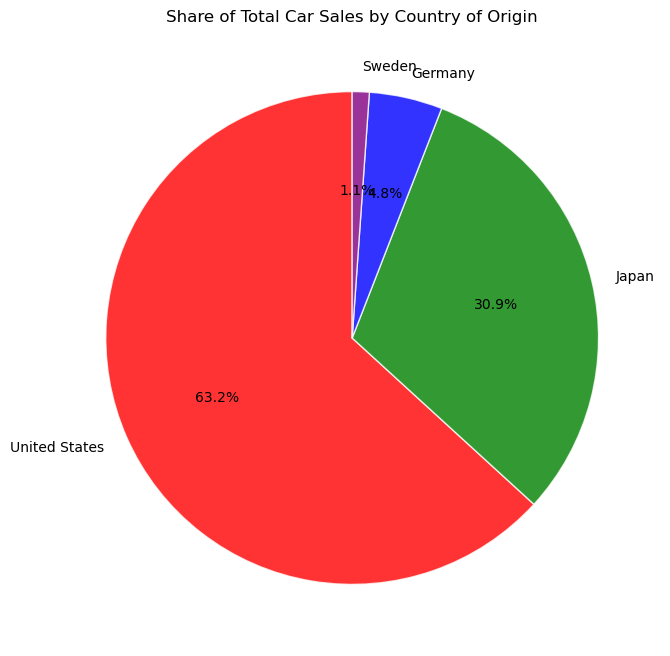

In [37]:
sales_by_country = df.groupby('country')['sales'].sum()
sales_by_country = sales_by_country.sort_values(ascending=False)
print(sales_by_country)
colors = ['red', 'green', 'blue', 'purple']
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(sales_by_country.values,
       labels=sales_by_country.index,
       colors=colors,
       autopct='%1.1f%%',
       startangle=90,
       wedgeprops={'edgecolor': 'white', 'alpha': 0.8})
ax.set_title('Share of Total Car Sales by Country of Origin')
plt.show()